# Proof of Concept: 60-Second Relative Price Forecasting for Market Makers

**CSET211 Statistical Machine Learning | Milestone 2: dataset, EDA and model comparison**

Arshpreet Singh (S25CSEU0980), Batch 33, Semester III

Dataset: [Optiver - Trading at the Close](https://www.kaggle.com/competitions/optiver-trading-at-the-close/data) (Kaggle). Place `train.csv` in the `data/` folder before running.

The loading, feature and model code is in `src/`. This notebook runs it step by step, shows every output and explains what each graph tells us. Figures are saved to `figures/` and result tables to `results/`.

## 1. Setup

In [1]:
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, '..')
from src import config, data, models

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

config.FIGURES_DIR.mkdir(exist_ok=True)
config.RESULTS_DIR.mkdir(exist_ok=True)


def save(fig, name):
    fig.savefig(config.FIGURES_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

## 2. Load Dataset

In [2]:
raw = data.load_raw()

print(f'{raw.shape[0]:,} rows x {raw.shape[1]} columns')

5,237,980 rows x 17 columns


In [3]:
raw.head()

,stock_id,date_id,seconds_in_bucket,imbalance_size,imbalance_buy_sell_flag,reference_price,matched_size,far_price,near_price,bid_price,bid_size,ask_price,ask_size,wap,target,time_id,row_id
0,0,0,0,3180602.69,1,0.999812,13380276.64,NaN,NaN,0.999812,60651.50,1.000026,8493.03,1.0,-3.029704,0,0_0_0
1,1,0,0,166603.91,-1,0.999896,1642214.25,NaN,NaN,0.999896,3233.04,1.000660,20605.09,1.0,-5.519986,0,0_0_1
2,2,0,0,302879.87,-1,0.999561,1819368.03,NaN,NaN,0.999403,37956.00,1.000298,18995.00,1.0,-8.389950,0,0_0_2
3,3,0,0,11917682.27,-1,1.000171,18389745.62,NaN,NaN,0.999999,2324.90,1.000214,479032.40,1.0,-4.010200,0,0_0_3
4,4,0,0,447549.96,-1,0.999532,17860614.95,NaN,NaN,0.999394,16485.54,1.000016,434.10,1.0,-7.349849,0,0_0_4


In [4]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5237980 entries, 0 to 5237979
Data columns (total 17 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   stock_id                 int64  
 1   date_id                  int64  
 2   seconds_in_bucket        int64  
 3   imbalance_size           float64
 4   imbalance_buy_sell_flag  int64  
 5   reference_price          float64
 6   matched_size             float64
 7   far_price                float64
 8   near_price               float64
 9   bid_price                float64
 10  bid_size                 float64
 11  ask_price                float64
 12  ask_size                 float64
 13  wap                      float64
 14  target                   float64
 15  time_id                  int64  
 16  row_id                   object 
dtypes: float64(11), int64(5), object(1)
memory usage: 679.4+ MB


## 3. Dataset Overview

In [5]:
print('Stocks:', raw['stock_id'].nunique())
print(f"Trading days: {raw['date_id'].nunique()} (date_id {raw['date_id'].min()} to {raw['date_id'].max()})")
print(f"Snapshots per day: {raw['seconds_in_bucket'].nunique()} "
      f"({raw['seconds_in_bucket'].min()} to {raw['seconds_in_bucket'].max()} s, every 10 s)")
print()
print('Target (bps):')
print(raw['target'].describe().round(4).to_string())
print('Missing targets:', raw['target'].isna().sum())

Stocks: 200
Trading days: 481 (date_id 0 to 480)
Snapshots per day: 55 (0 to 540 s, every 10 s)

Target (bps):
count    5.237892e+06
mean    -4.760000e-02
std      9.452900e+00
min     -3.852898e+02
25%     -4.559800e+00
50%     -6.020000e-02
75%      4.409600e+00
max      4.460704e+02
Missing targets: 88


The target is the stock's price move over the next 60 seconds **minus** the move of a market index over the same 60 seconds, in basis points (1 bp = 0.01%). Because it is relative to the market, the features below include market-relative versions of the stock's signals.

## 4. Missing Values

In [6]:
missing = raw.isnull().sum()
missing = pd.DataFrame({'Missing': missing, 'Missing %': (missing / len(raw) * 100).round(2)})
missing = missing[missing['Missing'] > 0].sort_values('Missing %', ascending=False)
missing

,Missing,Missing %
far_price,2894342,55.26
near_price,2857180,54.55
imbalance_size,220,0.00
matched_size,220,0.00
reference_price,220,0.00
bid_price,220,0.00
ask_price,220,0.00
wap,220,0.00
target,88,0.00


`far_price` and `near_price` are only published from 300 s onward, so they are missing for about half of every auction. This is by design, not a data error. Around 220 rows have no order-book prices at all, and 88 rows have no target.

## 5. Stock Selection (3 + 1 + 1)

Stocks are ranked by average `matched_size` (the dollar value that can be matched in the auction) as a measure of liquidity. We keep the 3 most liquid stocks, the median stock and the least liquid stock, with all 481 trading days for each.

In [7]:
tiers, liquidity = data.select_stocks(raw)
selected = list(tiers)

for sid, tier in tiers.items():
    print(f'stock {sid:>3}  {tier:<4}  avg matched size = {liquidity[sid]:>15,.0f}')

stock 112  High  avg matched size =     893,969,959
stock  45  High  avg matched size =     799,247,595
stock 168  High  avg matched size =     485,907,607
stock  89  Mid   avg matched size =      17,024,329
stock 143  Low   avg matched size =         653,206


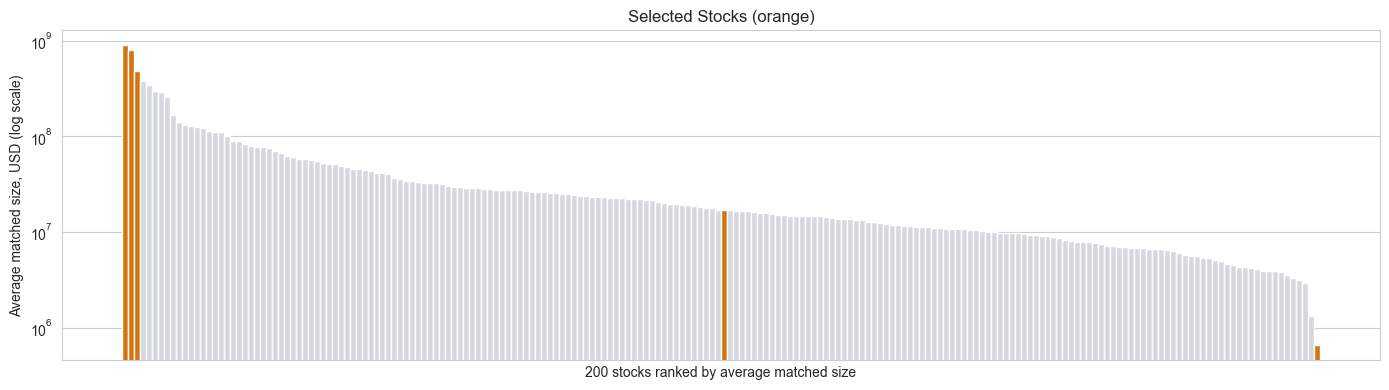

In [8]:
fig, ax = plt.subplots(figsize=(14, 4))
colors = ['#D4740E' if s in selected else '#D5D8DC' for s in liquidity.index]
ax.bar(range(len(liquidity)), liquidity.values, color=colors, width=1.0)
ax.set_yscale('log')
ax.set_xticks([])
ax.set_xlabel(f'{len(liquidity)} stocks ranked by average matched size')
ax.set_ylabel('Average matched size, USD (log scale)')
ax.set_title('Selected Stocks (orange)')
plt.tight_layout()
save(fig, '01_stock_selection')
plt.show()

**What the graph shows:** all 200 stocks ranked by average matched size on a log scale, with the five selected stocks in orange. Liquidity falls smoothly from about 894 million USD (stock 112) to 0.65 million USD (stock 143), a gap of more than 1,000 times.

**What we learn:** the selection covers the most liquid stocks, a typical stock and the least liquid one, so every result can be checked across the full liquidity range. Because sizes differ by three orders of magnitude, the features use ratios and basis points instead of raw dollar amounts.

## 6. Feature Engineering

Ten features in three groups. All price features are expressed in basis points relative to a reference so that stocks of different size are comparable.

**A. Order book** (available at every snapshot)

| Feature | Formula |
|---|---|
| imbalance_ratio | imbalance_size x imbalance_buy_sell_flag / (matched_size + 1) |
| liquidity_imbalance | (bid_size - ask_size) / (bid_size + ask_size + 1) |
| spread | (ask_price - bid_price) / wap, in bps |
| ref_price_dev | (wap - reference_price) / reference_price, in bps |
| return_60s | change in wap over the previous 60 s, in bps |

**B. Auction prices** (published only from 300 s, set to 0 when missing)

| Feature | Formula |
|---|---|
| near_price_dev | (near_price - reference_price) / reference_price, in bps |
| far_price_dev | (far_price - reference_price) / reference_price, in bps |

**C. Market context** (stock compared with the average of all stocks trading at the same second, up to 200)

| Feature | Formula |
|---|---|
| rel_imbalance | imbalance_ratio - market average imbalance_ratio |
| rel_return_60s | return_60s - market average return_60s |
| seconds_in_bucket | time since the auction started |

The market averages need every stock, so `imbalance_ratio` and `return_60s` are computed on the full dataset before filtering to the 5 selected stocks (`data.add_features`).

In [9]:
df = data.add_features(raw, selected)

print(f'{len(raw):,} -> {len(df):,} rows after keeping the 5 selected stocks')
print(f"Auction prices available in {df['far_price'].notna().mean():.1%} of rows")

5,237,980 -> 132,275 rows after keeping the 5 selected stocks
Auction prices available in 44.2% of rows


## 7. Data Cleaning

1. Drop rows with a missing target.
2. Set auction features to 0 when `near_price` or `far_price` is missing (mostly before 300 s, when they are not yet published).
3. Set `return_60s` and `rel_return_60s` to 0 in the first 60 s of each day, when there is no earlier price to compare with.
4. Replace infinite values and drop rows with missing order-book prices.

Extreme feature values are clipped later, using limits taken from the training data only.

In [10]:
n_before = len(df)
df = data.clean(df)
df['liquidity_tier'] = df['stock_id'].map(tiers)

print(f'Dropped {n_before - len(df)} rows with a missing target or missing order-book prices')
print(f'Final: {len(df):,} rows, {len(config.FEATURES)} features')

Dropped 0 rows with a missing target or missing order-book prices
Final: 132,275 rows, 10 features


## 8. Save Preprocessed Data

The cleaned dataset (identifiers, 10 features and target) is saved as `data/optiver_preprocessed.csv` so later milestones can start from here without the full `train.csv`. Reading it back checks the file.

In [11]:
data.save_preprocessed(df)
pre = data.load_preprocessed()

print(f'Saved {config.PREPROCESSED_PATH.name}: {pre.shape[0]:,} rows x {pre.shape[1]} columns')
pre.head()

Saved optiver_preprocessed.csv: 132,275 rows x 14 columns


,stock_id,liquidity_tier,date_id,imbalance_ratio,liquidity_imbalance,spread,ref_price_dev,return_60s,near_price_dev,far_price_dev,rel_imbalance,rel_return_60s,seconds_in_bucket,target
0,45,High,0,0.124831,0.374952,1.050000,1.430205,0.0,0.0,0.0,-0.001870,0.0,0,-1.440048
1,45,High,0,0.114570,-0.301341,0.700009,-0.110000,0.0,0.0,0.0,0.046393,0.0,10,1.510382
2,45,High,0,0.109795,-0.038887,1.049581,-0.549750,0.0,0.0,0.0,0.037496,0.0,20,-0.600219
3,45,High,0,0.106452,-0.628443,1.049614,-0.859610,0.0,0.0,0.0,0.041568,0.0,30,0.100136
4,45,High,0,0.090045,-0.569304,0.349814,-0.269849,0.0,0.0,0.0,0.033608,0.0,40,0.829697


## 9. Feature Distributions

In [12]:
df[config.FEATURES].describe()

,imbalance_ratio,liquidity_imbalance,spread,ref_price_dev,return_60s,near_price_dev,far_price_dev,rel_imbalance,rel_return_60s,seconds_in_bucket
count,132275.000000,132275.000000,132275.000000,132275.000000,132275.000000,132275.000000,132275.000000,132275.000000,132275.000000,132275.000000
mean,0.046221,-0.006657,7.010684,-0.319383,0.055375,-0.697415,6.897852,0.045535,0.036546,270.000000
std,0.717842,0.542483,11.405289,6.956243,10.053417,62.440400,1396.619752,0.709911,7.973370,158.745679
min,-8.842893,-0.999788,0.149576,-66.465281,-132.154223,-978.227374,-9995.872260,-8.828020,-132.470854,0.000000
25%,-0.068799,-0.441470,0.750357,-0.908910,-4.008347,0.000000,0.000000,-0.069508,-3.090817,130.000000
50%,0.000000,-0.000123,1.591966,-0.039840,0.000000,0.000000,0.000000,-0.000593,0.000000,270.000000
75%,0.077982,0.428516,7.030829,0.681847,4.073177,0.000000,0.000000,0.077533,3.201644,410.000000
max,30.185947,0.999751,116.330000,122.286494,244.908014,1000.001981,377681.480153,30.213473,245.189260,540.000000


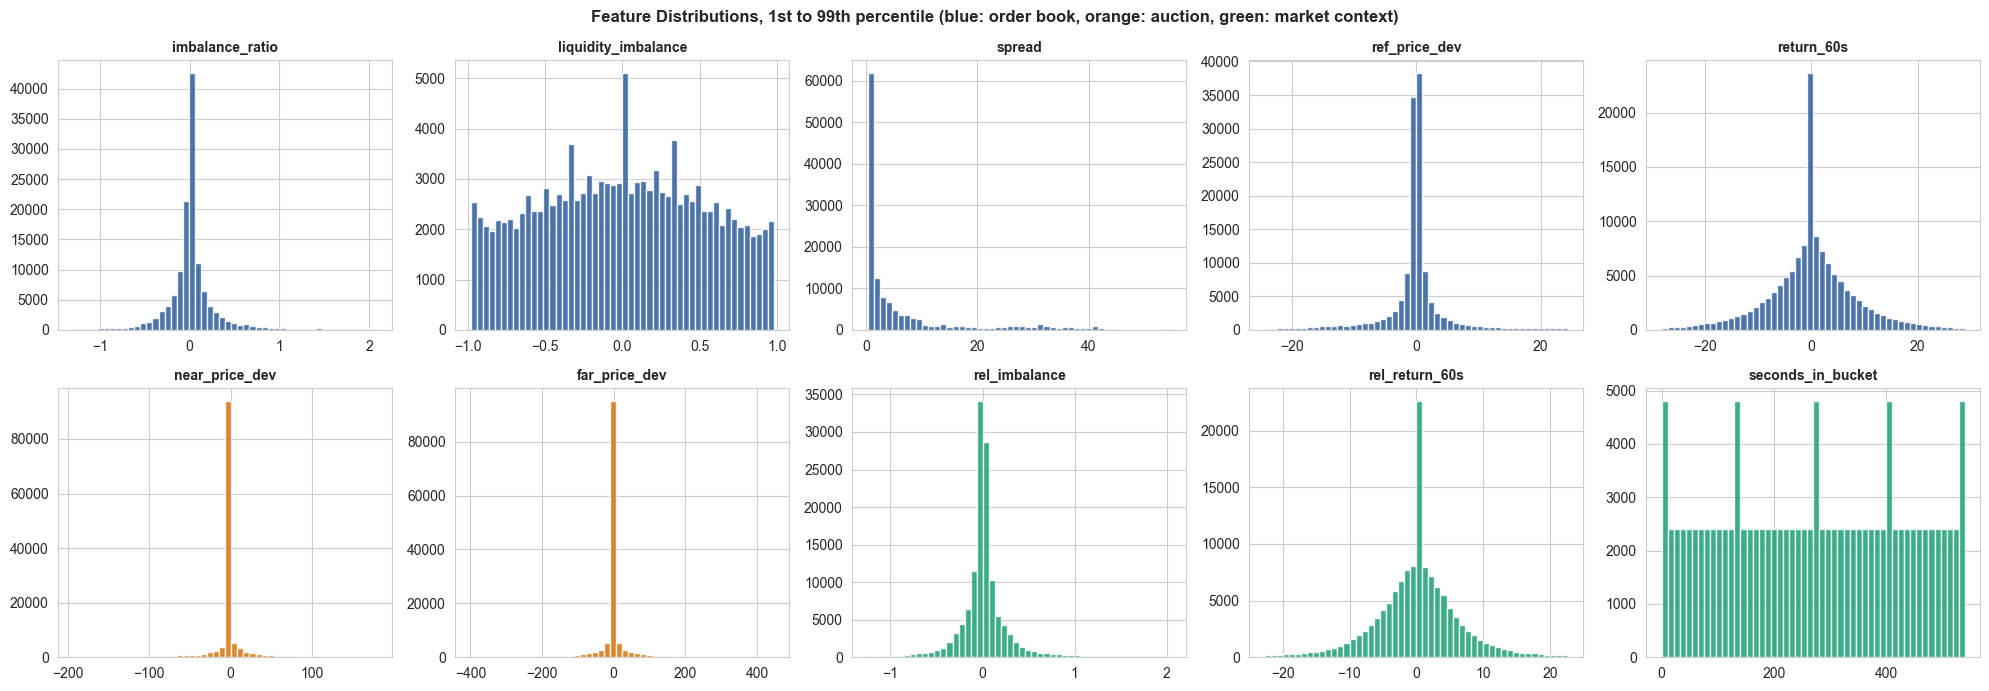

In [13]:
group_color = {c: '#2E5C9A' for c in config.ORDER_BOOK}
group_color.update({c: '#D4740E' for c in config.AUCTION})
group_color.update({c: '#1B9E77' for c in config.MARKET})

fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.flat, config.FEATURES):
    lo, hi = df[col].quantile([0.01, 0.99])
    values = df.loc[df[col].between(lo, hi), col]
    ax.hist(values, bins=50, color=group_color[col], alpha=0.85, edgecolor='white')
    ax.locator_params(axis='x', nbins=5)
    ax.set_title(col, fontsize=10, fontweight='bold')
plt.suptitle('Feature Distributions, 1st to 99th percentile (blue: order book, orange: auction, green: market context)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
save(fig, '02_feature_distributions')
plt.show()

**What the graph shows:** each feature between its 1st and 99th percentile. Most order-book and market features are centred on zero with long tails on both sides, while `spread` is always positive and skewed to the right. `near_price_dev` and `far_price_dev` have a tall bar at 0, and `return_60s` and `rel_return_60s` a smaller one, because they are set to 0 when the value does not exist yet (before 300 s, or in the first minute). `seconds_in_bucket` is flat because every time stamp appears equally often; its five taller bars only come from 55 time stamps falling into 50 bins.

**What we learn:** the spikes at zero are expected, not errors. The tails continue far beyond the plotted range (`far_price_dev` reaches 377,681 bps and `imbalance_ratio` 30.2, see the table above), so the features are clipped using limits from the training days only.

## 10. Target Variable

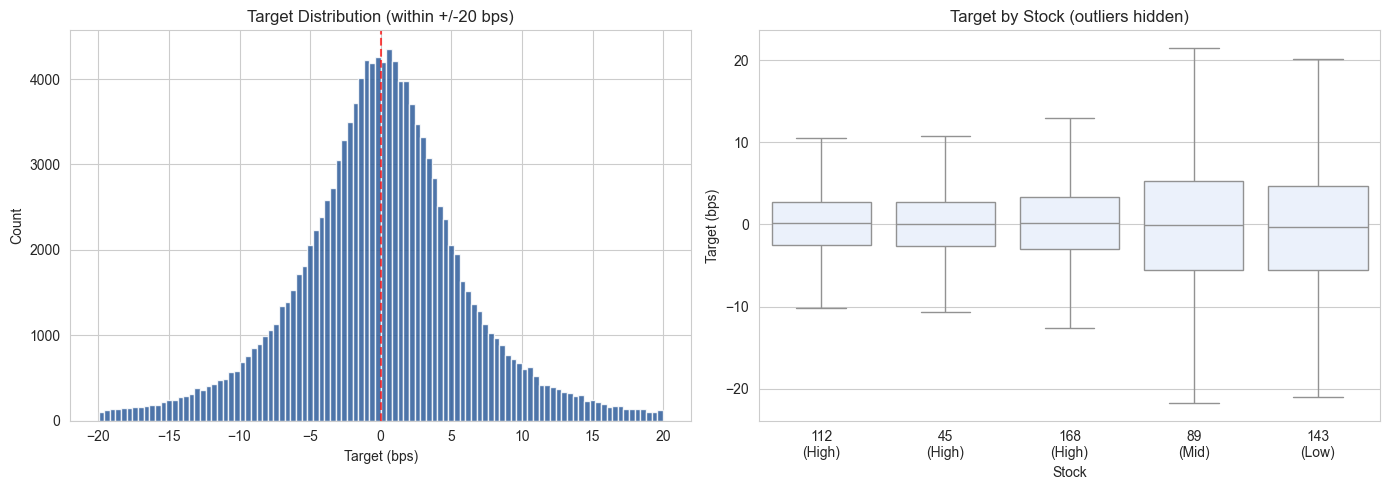

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df.loc[df['target'].between(-20, 20), 'target'], bins=100,
             color='#2E5C9A', alpha=0.85, edgecolor='white')
axes[0].axvline(0, color='red', linestyle='--', alpha=0.7)
axes[0].set_xlabel('Target (bps)')
axes[0].set_ylabel('Count')
axes[0].set_title('Target Distribution (within +/-20 bps)')

sns.boxplot(data=df, x='stock_id', y='target', order=selected,
            showfliers=False, color='#E8F0FE', ax=axes[1])
axes[1].set_xticks(range(len(selected)), [f'{s}\n({tiers[s]})' for s in selected])
axes[1].set_xlabel('Stock')
axes[1].set_ylabel('Target (bps)')
axes[1].set_title('Target by Stock (outliers hidden)')

plt.tight_layout()
save(fig, '03_target')
plt.show()

**What the graph shows:** on the left, the target within +/-20 bps is a symmetric bell centred almost exactly on zero (over the full dataset the mean is -0.048 bps and the median -0.060 bps, section 3). On the right, the boxes (middle 50% of moves) of the mid stock 89 and the low-liquidity stock 143 are roughly twice as tall as those of the three liquid stocks.

**What we learn:** there is no steady drift up or down, so always predicting the training mean is a fair baseline to beat. The tails are fat (the full range is -385 to +446 bps), which is why the models are scored with MAE and XGBoost is trained with an absolute-error loss. Volatility depends on the stock, so each stock is later compared with its own baseline.

## 11. Feature-Target Correlations

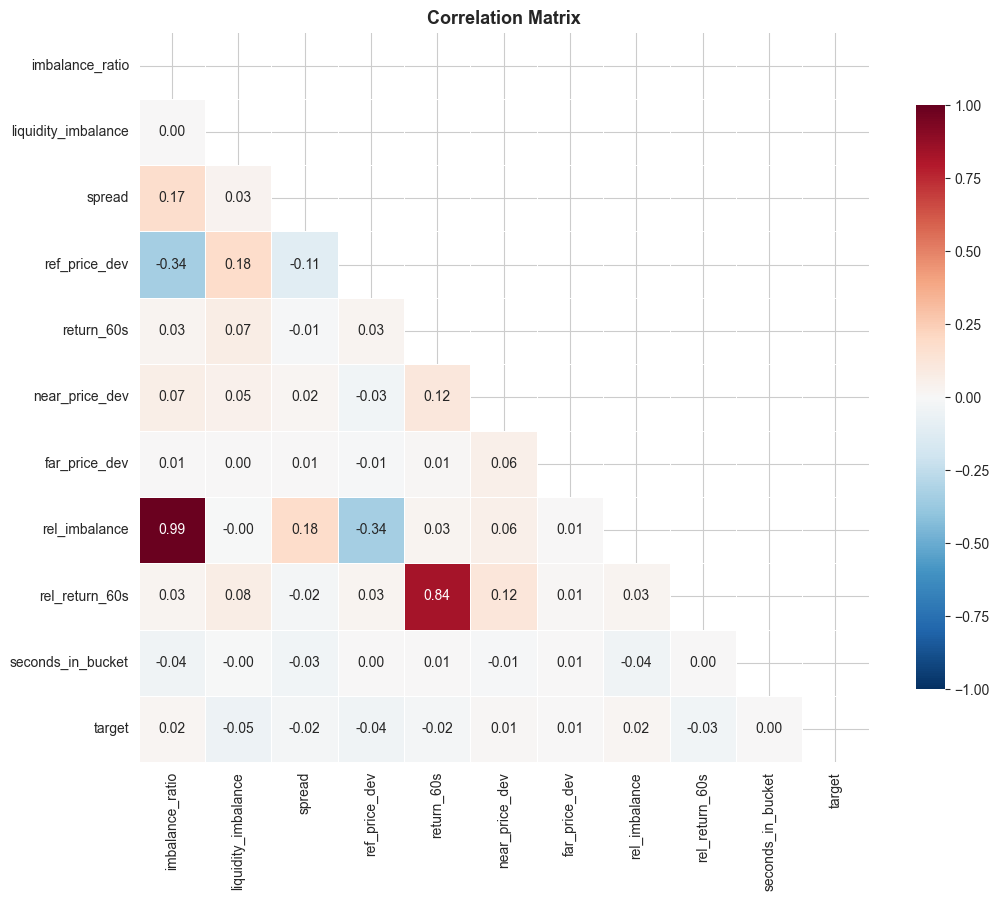

liquidity_imbalance   -0.0494
ref_price_dev         -0.0393
rel_return_60s        -0.0324
return_60s            -0.0232
imbalance_ratio        0.0197
rel_imbalance          0.0180
spread                -0.0178
near_price_dev         0.0136
far_price_dev          0.0054
seconds_in_bucket      0.0006
Name: target, dtype: float64

In [15]:
corr = df[config.FEATURES + ['target']].corr()

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Correlation Matrix', fontsize=13, fontweight='bold')
plt.tight_layout()
save(fig, '04_correlations')
plt.show()

corr['target'].drop('target').sort_values(key=abs, ascending=False).round(4)

**What the graph shows:** pairwise correlations between the ten features and the target. In the bottom row (the target) every value lies between -0.05 and +0.05; the strongest are `liquidity_imbalance` (-0.049), `ref_price_dev` (-0.039) and `rel_return_60s` (-0.032). Two feature pairs are near duplicates: `imbalance_ratio` with `rel_imbalance` (0.99) and `return_60s` with `rel_return_60s` (0.84).

**What we learn:** no feature has a strong straight-line link with the target, so gains will be small and a linear model may not beat the baseline; a more flexible model is worth testing. The negative return correlations point to short-term reversal: a stock that just beat the market tends to give some of it back. A likely reason for the negative `liquidity_imbalance`: when the bid side is heavier, the weighted price (wap) sits closer to the ask, so it tends to come back down. The near-duplicate pairs are kept so the ablation study can test each group; SHAP in Milestone 3 will show whether `rel_imbalance` adds anything.

## 12. Features by Liquidity Tier

In [16]:
df.groupby('liquidity_tier')[config.FEATURES].mean().loc[['High', 'Mid', 'Low']]

,imbalance_ratio,liquidity_imbalance,spread,ref_price_dev,return_60s,near_price_dev,far_price_dev,rel_imbalance,rel_return_60s,seconds_in_bucket
liquidity_tier,,,,,,,,,,
High,-0.011476,-0.013665,1.299886,0.002916,0.182580,-2.171117,-2.993868,-0.012162,0.163750,270.0
Mid,0.000812,-0.024572,5.537733,-0.033752,-0.078431,0.588396,25.328204,0.000127,-0.097261,270.0
Low,0.264720,0.032279,25.616029,-1.571912,-0.192431,2.437879,18.142656,0.264034,-0.211261,270.0


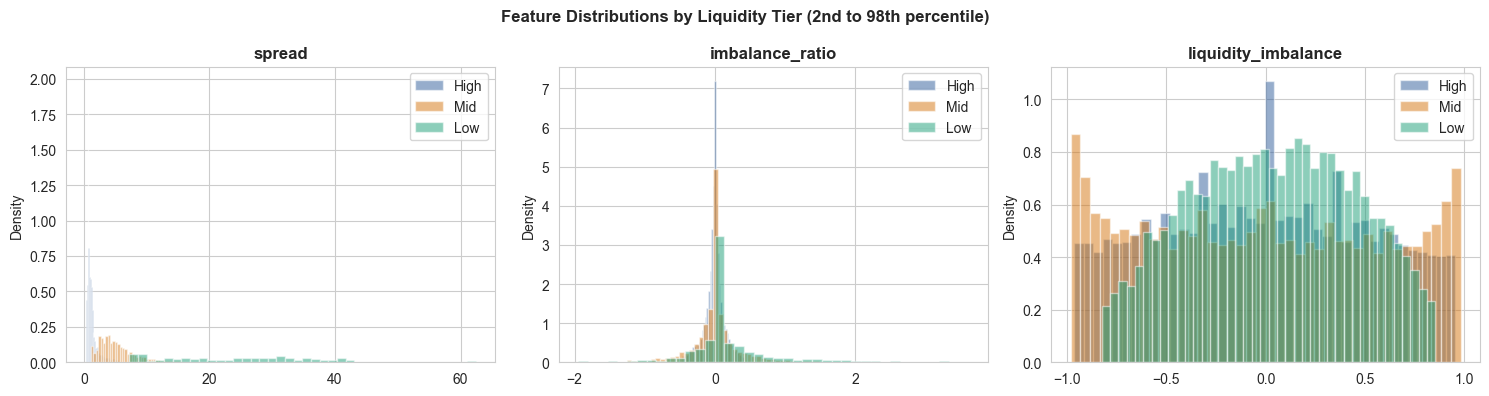

In [17]:
tier_colors = {'High': '#2E5C9A', 'Mid': '#D4740E', 'Low': '#1B9E77'}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feat in zip(axes, ['spread', 'imbalance_ratio', 'liquidity_imbalance']):
    for tier, color in tier_colors.items():
        values = df.loc[df['liquidity_tier'] == tier, feat]
        lo, hi = values.quantile([0.02, 0.98])
        ax.hist(values[values.between(lo, hi)], bins=40, alpha=0.5, density=True, label=tier, color=color)
    ax.locator_params(axis='x', nbins=5)
    ax.set_title(feat, fontweight='bold')
    ax.set_ylabel('Density')
    ax.legend()
plt.suptitle('Feature Distributions by Liquidity Tier (2nd to 98th percentile)', fontsize=12, fontweight='bold')
plt.tight_layout()
save(fig, '05_liquidity_tiers')
plt.show()

**What the graph shows:** three features split by liquidity tier. The spreads barely overlap: on average 1.30 bps for the three liquid stocks, 5.54 bps for stock 89 and 25.62 bps for stock 143. `imbalance_ratio` peaks at zero in every tier but is wider for the low-liquidity stock. `liquidity_imbalance` has a different shape in each tier: the mid stock often sits near -1 or +1 (one side of the book much heavier), while the low-liquidity stock stays closer to the middle.

**What we learn:** the same feature behaves differently at different liquidity levels, so a model that works for liquid stocks is not guaranteed to work for illiquid ones. This is why results are also reported stock by stock (section 17), and why per-tier models will be compared with the pooled model in Milestone 3.

## 13. Chronological Train-Test Splits

Two splits on `date_id`, with no shuffling, so the model is always tested on days after the ones it was trained on:

- **70/30:** first 70% of trading days for training, last 30% for testing
- **80/20:** first 80% of trading days for training, last 20% for testing

For each split, features are clipped to the 1st and 99th percentile of the training data, and the training target is clipped the same way so a few extreme moves do not dominate the fit. The test target is never changed.

In [18]:
splits = models.make_splits(df)

for name, s in splits.items():
    train_days, test_days = s['train_days'], s['test_days']
    print(f"{name}: train date_id {train_days[0]}-{train_days[1]} ({len(s['X_train']):,} rows) | "
          f"test date_id {test_days[0]}-{test_days[1]} ({len(s['X_test']):,} rows)")

70/30: train date_id 0-335 (92,400 rows) | test date_id 336-480 (39,875 rows)
80/20: train date_id 0-383 (105,600 rows) | test date_id 384-480 (26,675 rows)


## 14. Feature Sets for the Ablation Study

Each set adds one group to the previous one (`config.FEATURE_SETS`):

- **A: Order book** (5 features)
- **B: + Auction** (7 features)
- **C: + Market context** (all 10 features)

Comparing A with B shows whether auction prices add information, and B with C whether comparing the stock with the market does.

## 15. Model Training (3 models x 3 feature sets x 2 splits = 18 experiments)

- **Linear Regression**: baseline linear model
- **Polynomial Regression (degree 2)**: features standardised, expanded to squares and pairwise products, then fitted with linear regression
- **XGBoost**: gradient-boosted trees (300 trees, depth 4, learning rate 0.05, 80% row and column sampling), trained with the absolute-error objective so it optimises the same quantity it is scored on

Each split also has a naive baseline that predicts the training-set mean target for every row.

Two metrics on the test set:
- **MAE** in basis points (lower is better)
- **Direction accuracy**: share of rows where the predicted sign (up or down) matches the actual sign

In [19]:
results, predictions = models.run_experiments(splits)
results.to_csv(config.RESULTS_DIR / 'experiments.csv', index=False)

print(f'\n{len(predictions)} experiments completed')

70/30 | A: Order book  | Linear             | MAE 5.0149
70/30 | A: Order book  | Polynomial (deg 2) | MAE 5.0086
70/30 | A: Order book  | XGBoost            | MAE 5.0135
70/30 | B: + Auction   | Linear             | MAE 5.0164
70/30 | B: + Auction   | Polynomial (deg 2) | MAE 5.0199
70/30 | B: + Auction   | XGBoost            | MAE 5.0045
70/30 | C: + Market    | Linear             | MAE 5.0191
70/30 | C: + Market    | Polynomial (deg 2) | MAE 5.0271
70/30 | C: + Market    | XGBoost            | MAE 4.9589
80/20 | A: Order book  | Linear             | MAE 4.7880
80/20 | A: Order book  | Polynomial (deg 2) | MAE 4.7797
80/20 | A: Order book  | XGBoost            | MAE 4.7763
80/20 | B: + Auction   | Linear             | MAE 4.7938
80/20 | B: + Auction   | Polynomial (deg 2) | MAE 4.7953
80/20 | B: + Auction   | XGBoost            | MAE 4.7738
80/20 | C: + Market    | Linear             | MAE 4.7966
80/20 | C: + Market    | Polynomial (deg 2) | MAE 4.8058
80/20 | C: + Market    | XGBoos

## 16. Results

In [20]:
model_order = ['Linear', 'Polynomial (deg 2)', 'XGBoost']
set_order = list(config.FEATURE_SETS)

for split_name in splits:
    part = results[results['Split'] == split_name]
    base = part[part['Model'] == 'Naive baseline'].iloc[0]
    trained = part[part['Model'] != 'Naive baseline']
    best = trained.loc[trained['MAE'].idxmin()]

    print(f"Split {split_name}  |  naive baseline: MAE {base['MAE']:.4f} bps, direction {base['Direction %']:.1f}%")
    display(trained.pivot(index='Model', columns='Features', values='MAE').loc[model_order, set_order].round(4))
    display(trained.pivot(index='Model', columns='Features', values='Direction %').loc[model_order, set_order].round(1))
    print(f"Best: {best['Model']} with {best['Features']} -> MAE {best['MAE']:.4f} bps "
          f"({best['Improvement %']:+.2f}% vs baseline)\n")

Split 70/30  |  naive baseline: MAE 5.0037 bps, direction 48.5%


Features,A: Order book,B: + Auction,C: + Market
Model,,,
Linear,5.0149,5.0164,5.0191
Polynomial (deg 2),5.0086,5.0199,5.0271
XGBoost,5.0135,5.0045,4.9589


Features,A: Order book,B: + Auction,C: + Market
Model,,,
Linear,52.0,51.8,51.6
Polynomial (deg 2),51.4,51.4,52.3
XGBoost,52.5,53.2,54.0


Best: XGBoost with C: + Market -> MAE 4.9589 bps (+0.90% vs baseline)

Split 80/20  |  naive baseline: MAE 4.7798 bps, direction 48.3%


Features,A: Order book,B: + Auction,C: + Market
Model,,,
Linear,4.7880,4.7938,4.7966
Polynomial (deg 2),4.7797,4.7953,4.8058
XGBoost,4.7763,4.7738,4.7310


Features,A: Order book,B: + Auction,C: + Market
Model,,,
Linear,52.0,51.7,51.4
Polynomial (deg 2),51.9,51.5,52.1
XGBoost,52.7,52.7,53.7


Best: XGBoost with C: + Market -> MAE 4.7310 bps (+1.02% vs baseline)



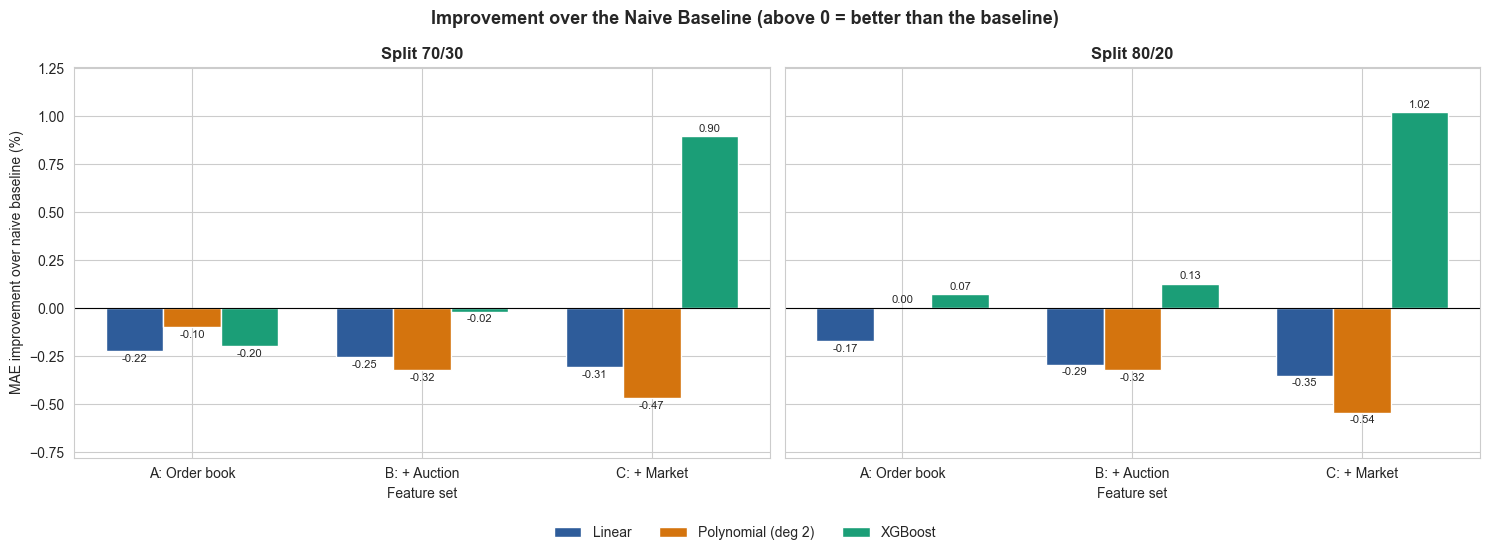

In [21]:
model_colors = {'Linear': '#2E5C9A', 'Polynomial (deg 2)': '#D4740E', 'XGBoost': '#1B9E77'}
width = 0.25
x = np.arange(len(set_order))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, split_name in zip(axes, splits):
    part = results[results['Split'] == split_name].set_index(['Model', 'Features'])
    for i, (model_name, color) in enumerate(model_colors.items()):
        values = [part.loc[(model_name, s), 'Improvement %'] for s in set_order]
        bars = ax.bar(x + (i - 1) * width, values, width, label=model_name, color=color)
        ax.bar_label(bars, fmt='%.2f', fontsize=8, padding=2)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.margins(y=0.15)
    ax.set_xticks(x, set_order)
    ax.set_xlabel('Feature set')
    ax.set_title(f'Split {split_name}', fontsize=12, fontweight='bold')
axes[0].set_ylabel('MAE improvement over naive baseline (%)')

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False)
plt.suptitle('Improvement over the Naive Baseline (above 0 = better than the baseline)', fontsize=13, fontweight='bold')
plt.tight_layout(rect=[0, 0.06, 1, 1])
save(fig, '06_model_comparison')
plt.show()

**What the graph shows:** how much lower each model's test MAE is than the naive baseline, for every feature set on both splits; bars above zero beat the baseline. Only XGBoost with all ten features is clearly above zero: 0.90% on 70/30 and 1.02% on 80/20. Linear regression is below zero on every set (-0.17% to -0.35%), and Polynomial regression drops further with each group added, down to -0.54%. For XGBoost, adding auction prices changes little, while adding market context gives the jump.

**What we learn:** a straight line, or squares and products of the features, do not capture the signal, but a tree model does once market-relative features are added. XGBoost with feature set C is the selected model, and market context is the most useful feature group, which fits a target that is itself defined relative to the market.

## 17. Cross-Liquidity Generalization Test

XGBoost with all features, scored separately on each stock's test rows. Stocks differ in volatility, so each stock's MAE is compared with the naive baseline on the same rows.

In [22]:
per_stock = models.per_stock_results(splits, predictions, tiers)
per_stock.to_csv(config.RESULTS_DIR / 'per_stock.csv', index=False)
per_stock.round(4)

,Split,Stock,Tier,Test rows,XGBoost MAE,Baseline MAE,Improvement %,Direction %
0,70/30,112,High,7975,3.0797,3.1006,0.6749,54.2320
1,70/30,45,High,7975,3.2778,3.3245,1.4052,55.3856
2,70/30,168,High,7975,4.0850,4.0989,0.3399,53.0784
3,70/30,89,Mid,7975,7.2379,7.3269,1.2156,55.5737
4,70/30,143,Low,7975,7.1141,7.1675,0.7455,51.8370
5,80/20,112,High,5335,2.9335,2.9480,0.4921,54.6204
6,80/20,45,High,5335,3.1508,3.1958,1.4073,55.5014
7,80/20,168,High,5335,3.8885,3.9174,0.7381,53.3271
8,80/20,89,Mid,5335,7.0825,7.1575,1.0471,55.1453
9,80/20,143,Low,5335,6.5998,6.6804,1.2064,50.0094


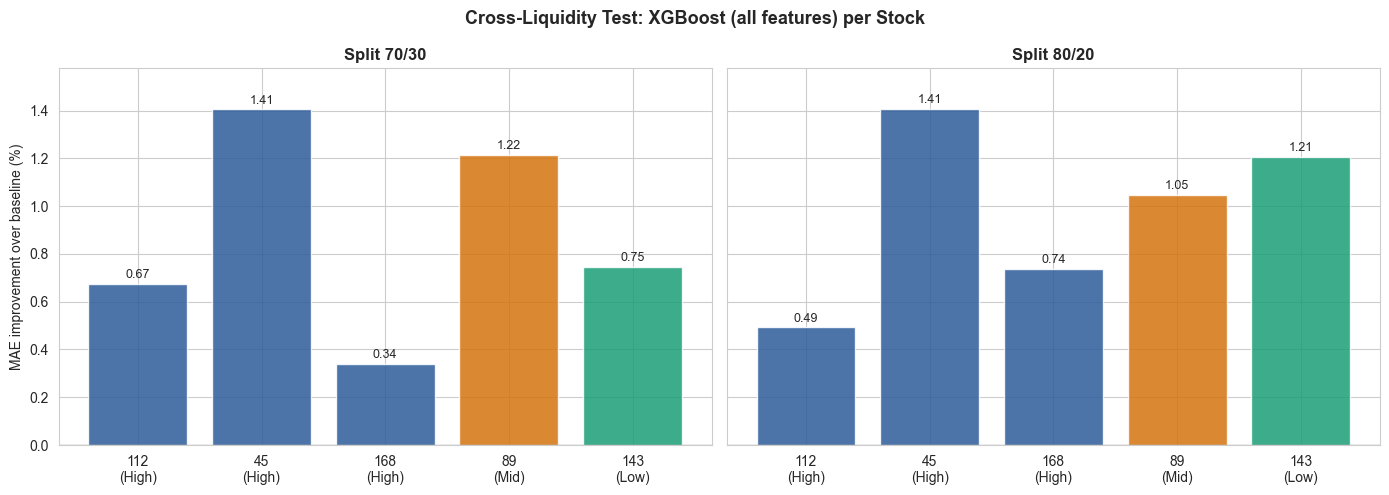

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, split_name in zip(axes, splits):
    part = per_stock[per_stock['Split'] == split_name]
    labels = [f'{r.Stock}\n({r.Tier})' for r in part.itertuples()]
    bars = ax.bar(labels, part['Improvement %'], color=[tier_colors[t] for t in part['Tier']], alpha=0.85)
    ax.bar_label(bars, fmt='%.2f', fontsize=9, padding=2)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.margins(y=0.12)
    ax.set_title(f'Split {split_name}', fontsize=12, fontweight='bold')
axes[0].set_ylabel('MAE improvement over baseline (%)')
plt.suptitle('Cross-Liquidity Test: XGBoost (all features) per Stock', fontsize=13, fontweight='bold')
plt.tight_layout()
save(fig, '07_per_stock')
plt.show()

**What the graph shows:** XGBoost (all features) against the baseline on each stock's own test rows. All ten bars are above zero: the gain ranges from 0.34% (stock 168) to 1.41% (stock 45), and the least liquid stock 143 gains 0.75% and 1.21%.

**What we learn:** the improvement is not limited to liquid stocks, so the market-relative features carry over across liquidity levels and one pooled model is a reasonable start. The table above adds a caveat: direction accuracy for stock 143 is only 51.8% and 50.0%, so for the least liquid stock the model mainly reduces the size of the error rather than calling the direction.

## 18. Robustness Check: 70/30 vs 80/20

A finding is treated as reliable only if it holds on both splits. The two test periods overlap (days 384 to 480 are in both), so this checks that the conclusions do not depend on one cut-off date; it is not a fully independent sample.

In [24]:
full = results[results['Features'] == 'C: + Market'].pivot(index='Model', columns='Split', values='MAE')
full = full.loc[model_order]
full['Difference'] = (full['70/30'] - full['80/20']).abs()
display(full.round(4))

print('Model ranking with all features (best to worst):')
for split_name in splits:
    print(f'  {split_name}: ' + ' > '.join(full[split_name].sort_values().index))

print('\nMAE change when each feature group is added (negative = better):')
for model_name in model_order:
    for split_name in splits:
        part = results[(results['Split'] == split_name) & (results['Model'] == model_name)]
        mae = part.set_index('Features')['MAE']
        print(f'  {model_name:<18} {split_name}:  + Auction {mae["B: + Auction"] - mae["A: Order book"]:+.4f}'
              f'  |  + Market {mae["C: + Market"] - mae["B: + Auction"]:+.4f}')

Split,70/30,80/20,Difference
Model,,,
Linear,5.0191,4.7966,0.2225
Polynomial (deg 2),5.0271,4.8058,0.2213
XGBoost,4.9589,4.7310,0.2278


Model ranking with all features (best to worst):
  70/30: XGBoost > Linear > Polynomial (deg 2)
  80/20: XGBoost > Linear > Polynomial (deg 2)

MAE change when each feature group is added (negative = better):
  Linear             70/30:  + Auction +0.0015  |  + Market +0.0027
  Linear             80/20:  + Auction +0.0058  |  + Market +0.0027
  Polynomial (deg 2) 70/30:  + Auction +0.0113  |  + Market +0.0072
  Polynomial (deg 2) 80/20:  + Auction +0.0155  |  + Market +0.0105
  XGBoost            70/30:  + Auction -0.0090  |  + Market -0.0456
  XGBoost            80/20:  + Auction -0.0025  |  + Market -0.0428


## 19. Findings

**Best model.** XGBoost with all 10 features is the only model that beats the naive baseline on both splits: MAE 4.9589 vs 5.0037 bps on 70/30 (0.90% lower) and 4.7310 vs 4.7798 bps on 80/20 (1.02% lower). It also predicts the direction of the move correctly 54.0% and 53.7% of the time. The baseline always predicts the training mean, which is slightly negative, so it is only right when the stock moves down (48.5% and 48.3%).

**Linear models.** With all features, Linear and Polynomial regression are slightly worse than the baseline on both splits, and adding feature groups makes them worse. Linear regression gets the direction right a little more often than the baseline (51 to 52%), but its errors are larger. Since only the tree model improves on the baseline, the useful signal is most likely non-linear.

**Feature groups (ablation).** For XGBoost, adding auction prices lowers MAE slightly (-0.0090 and -0.0025 bps), and adding market context gives the largest gain (-0.0456 and -0.0428 bps). The target is the stock's move relative to the market, so features that compare the stock with the market are the most useful. The negative correlation of rel_return_60s (-0.032) also shows short-term reversal: a stock that beat the market over the last 60 seconds tends to give some of that back.

**Cross-liquidity.** XGBoost has lower error than the baseline on all 5 stocks on both splits, by 0.34% to 1.41%, so the features carry over from the most liquid to the least liquid stock. Prediction is harder for less liquid stocks: the baseline error is 2.9 to 4.1 bps for the high-liquidity stocks and 6.7 to 7.3 bps for the mid and low ones. Direction accuracy ranges from 50.0% to 55.6% per stock and is lowest for the low-liquidity stock 143.

**Robustness.** All models score about 0.22 bps lower on the 80/20 split, but the baseline drops by the same amount, so that difference comes from a calmer test period rather than better models. The model ranking (XGBoost, then Linear, then Polynomial) and the direction of every feature-group effect are the same on both splits.

**Why the gains are small.** Price moves over 60 seconds are mostly noise: no feature has a correlation above 0.05 in absolute value with the target, and the target ranges from -385 to +446 bps. An improvement of around 1% in MAE with 54% direction accuracy is a realistic result for this horizon; a much larger gain would more likely point to data leakage than to a better model.

## 20. Summary and Next Steps

1. Loaded the Optiver closing-auction dataset (200 stocks, 481 days) and selected 5 stocks with the 3 + 1 + 1 liquidity strategy.
2. Built 10 features in three groups: order book, auction prices and market context.
3. Cleaned the data and saved the preprocessed dataset as `data/optiver_preprocessed.csv`.
4. Explored feature distributions, the target, correlations and differences between liquidity tiers.
5. Split the data chronologically in two ways (70/30 and 80/20), clipping extreme values using training data only.
6. Trained 3 models on 3 feature sets per split (18 experiments) and compared them with a naive baseline using MAE and direction accuracy.
7. Tested per-stock performance across liquidity tiers and checked that the results hold on both splits.

**Next (Milestone 3):** tune XGBoost with time-based cross-validation on the training days only, explain predictions with SHAP, compare per-tier models with the pooled model, and build a dashboard prototype.